In [1]:

!git clone https://github.com/Nasywarifqia/Kelompok-4_Team-Based-Project_Data-Mining.git

Cloning into 'Kelompok-4_Team-Based-Project_Data-Mining'...
remote: Enumerating objects: 214, done.
remote: Counting objects: 100% (214/214), done.
remote: Compressing objects: 100% (186/186), done.
remote: Total 214 (delta 57), reused 131 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (214/214), 8.85 MiB | 11.92 MiB/s, done.
Resolving deltas: 100% (57/57), done.


In [2]:

import os

folder = "/content/Kelompok-4_Team-Based-Project_Data-Mining/dataset/output"

print(os.listdir(folder))

['y_train.csv', 'encoding_map.json', 'X_train.csv', 'X_test.csv', 'scaler.pkl', 'y_test.csv']


In [3]:

import pandas as pd

# Membaca dataset training dan testing
X_train = pd.read_csv(folder + "/X_train.csv")
X_test = pd.read_csv(folder + "/X_test.csv")

y_train = pd.read_csv(folder + "/y_train.csv")
y_test = pd.read_csv(folder + "/y_test.csv")

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


In [4]:

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test :", y_test.shape)

Ukuran X_train: (4679, 30)
Ukuran X_test : (1170, 30)
Ukuran y_train: (4679, 1)
Ukuran y_test : (1170, 1)


In [5]:

# Melihat 5 data pertama
display(X_train.head())

# Melihat 5 label pertama
display(y_train.head())

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,1,-1,1,-1,1,-1,0,1,1,1,...,1,1,1,1,-1,-1,1,1,1,-1
1,1,-1,1,1,1,-1,-1,1,-1,1,...,1,1,1,1,-1,1,-1,1,1,1
2,1,-1,1,1,1,-1,0,1,1,1,...,1,1,1,-1,1,1,-1,1,0,1
3,1,-1,1,1,1,1,0,1,-1,1,...,1,1,1,-1,1,1,1,1,0,1
4,-1,1,-1,1,-1,-1,-1,1,-1,1,...,1,1,1,-1,-1,1,-1,1,1,1


,Result
0,1
1,0
2,0
3,0
4,0


In [6]:

print("Distribusi data training:")
print(y_train.iloc[:, 0].value_counts())

print("\nDistribusi data testing:")
print(y_test.iloc[:, 0].value_counts())

Distribusi data training:
Result
1    2415
0    2264
Name: count, dtype: int64

Distribusi data testing:
Result
1    604
0    566
Name: count, dtype: int64


In [7]:

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
import time

print("Library berhasil diimport!")

Library berhasil diimport!


In [8]:

# Membuat model Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Melatih model
start_time = time.time()

rf_model.fit(X_train, y_train.values.ravel())

training_time = time.time() - start_time

print("Model Random Forest berhasil dilatih!")
print("Waktu training:", round(training_time, 4), "detik")

Model Random Forest berhasil dilatih!
Waktu training: 0.3726 detik


In [9]:

# Melakukan prediksi
y_pred = rf_model.predict(X_test)

# Menghitung probabilitas prediksi
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Prediksi berhasil dilakukan!")

Prediksi berhasil dilakukan!


In [10]:

accuracy = accuracy_score(y_test.values.ravel(), y_pred)
precision = precision_score(y_test.values.ravel(), y_pred)
recall = recall_score(y_test.values.ravel(), y_pred)
f1 = f1_score(y_test.values.ravel(), y_pred)
roc_auc = roc_auc_score(y_test.values.ravel(), y_prob)

print("===== HASIL EVALUASI RANDOM FOREST =====")
print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))
print("ROC-AUC   :", round(roc_auc, 4))
print("Training Time:", round(training_time, 4), "detik")

===== HASIL EVALUASI RANDOM FOREST =====
Accuracy  : 0.9393
Precision : 0.9556
Recall    : 0.9255
F1-Score  : 0.9403
ROC-AUC   : 0.9845
Training Time: 0.3726 detik


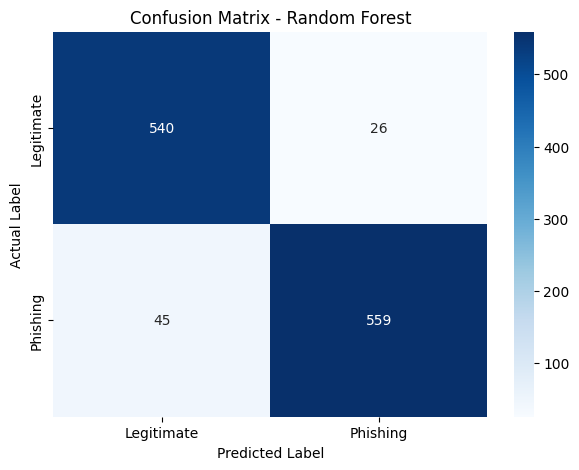

              precision    recall  f1-score   support

  Legitimate       0.92      0.95      0.94       566
    Phishing       0.96      0.93      0.94       604

    accuracy                           0.94      1170
   macro avg       0.94      0.94      0.94      1170
weighted avg       0.94      0.94      0.94      1170



In [11]:

# Membuat confusion matrix
cm = confusion_matrix(y_test.values.ravel(), y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print(classification_report(
    y_test.values.ravel(),
    y_pred,
    target_names=["Legitimate", "Phishing"]
))

In [13]:

# Daftar jumlah pohon yang akan diuji
jumlah_pohon = [50, 100, 200, 300]

# Menampung hasil eksperimen
hasil_eksperimen = []

for jumlah in jumlah_pohon:

    # Membuat model
    model = RandomForestClassifier(
        n_estimators=jumlah,
        random_state=42,
        n_jobs=-1
    )

    # Menghitung waktu training
    start = time.time()
    model.fit(X_train, y_train.values.ravel())
    waktu = time.time() - start

    # Melakukan prediksi
    prediksi = model.predict(X_test)
    probabilitas = model.predict_proba(X_test)[:, 1]

    # Menghitung evaluasi
    accuracy = accuracy_score(y_test.values.ravel(), prediksi)
    precision = precision_score(y_test.values.ravel(), prediksi)
    recall = recall_score(y_test.values.ravel(), prediksi)
    f1 = f1_score(y_test.values.ravel(), prediksi)
    auc = roc_auc_score(y_test.values.ravel(), probabilitas)

    # Menyimpan hasil
    hasil_eksperimen.append({
        "Jumlah Pohon": jumlah,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "Training Time": waktu
    })

    print("Selesai menguji", jumlah, "pohon")

print("Semua eksperimen selesai!")

Selesai menguji 50 pohon
Selesai menguji 100 pohon
Selesai menguji 200 pohon
Selesai menguji 300 pohon
Semua eksperimen selesai!


In [14]:

# Mengubah hasil eksperimen menjadi tabel
df_hasil = pd.DataFrame(hasil_eksperimen)

display(df_hasil.round(4))

,Jumlah Pohon,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time
0,50,0.9393,0.9571,0.9238,0.9402,0.9824,0.5415
1,100,0.9393,0.9556,0.9255,0.9403,0.9845,0.8899
2,200,0.9402,0.9572,0.9255,0.9411,0.9852,1.2806
3,300,0.9419,0.9573,0.9288,0.9429,0.9853,1.6339


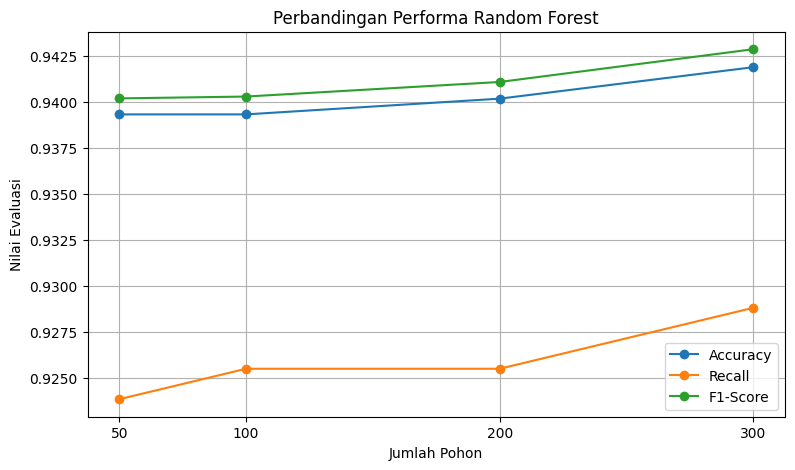

In [15]:

plt.figure(figsize=(9, 5))

plt.plot(
    df_hasil["Jumlah Pohon"],
    df_hasil["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    df_hasil["Jumlah Pohon"],
    df_hasil["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    df_hasil["Jumlah Pohon"],
    df_hasil["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.title("Perbandingan Performa Random Forest")
plt.xlabel("Jumlah Pohon")
plt.ylabel("Nilai Evaluasi")
plt.xticks(jumlah_pohon)
plt.legend()
plt.grid()
plt.show()

In [16]:

# Mengurutkan model berdasarkan Recall,
# kemudian F1-Score dan ROC-AUC
df_urut = df_hasil.sort_values(
    by=["Recall", "F1-Score", "ROC-AUC"],
    ascending=False
)

display(df_urut.round(4))

# Mengambil jumlah pohon terbaik
jumlah_terbaik = int(df_urut.iloc[0]["Jumlah Pohon"])

print("Jumlah pohon terbaik:", jumlah_terbaik)

,Jumlah Pohon,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time
3,300,0.9419,0.9573,0.9288,0.9429,0.9853,1.6339
2,200,0.9402,0.9572,0.9255,0.9411,0.9852,1.2806
1,100,0.9393,0.9556,0.9255,0.9403,0.9845,0.8899
0,50,0.9393,0.9571,0.9238,0.9402,0.9824,0.5415


Jumlah pohon terbaik: 300


In [18]:

# Training model Random Forest terbaik

import time
from sklearn.ensemble import RandomForestClassifier

# Membuat model dengan jumlah pohon terbaik
model_rf_final = RandomForestClassifier(
    n_estimators=jumlah_terbaik,
    random_state=42,
    n_jobs=-1
)

# Menghitung waktu training
waktu_mulai = time.time()

# Melatih model menggunakan data training
model_rf_final.fit(X_train, y_train.values.ravel())

waktu_training_final = time.time() - waktu_mulai

print("===== MODEL RANDOM FOREST FINAL =====")
print("Jumlah pohon :", jumlah_terbaik)
print("Waktu training :", round(waktu_training_final, 4), "detik")
print("Model berhasil dilatih!")

===== MODEL RANDOM FOREST FINAL =====
Jumlah pohon : 300
Waktu training : 2.6382 detik
Model berhasil dilatih!


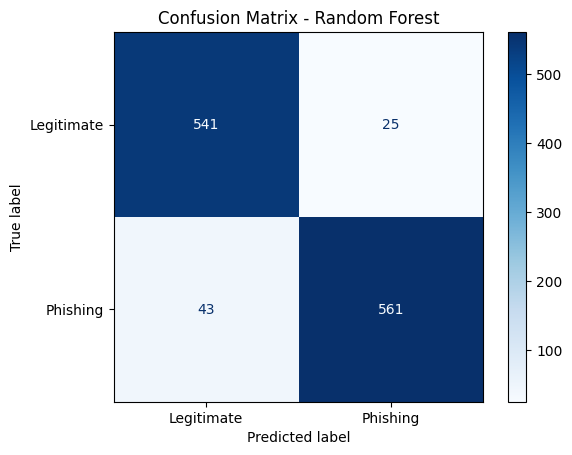

In [19]:

# Evaluasi menggunakan Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Melakukan prediksi pada data testing
y_pred_final = model_rf_final.predict(X_test)

# Menghitung Confusion Matrix
cm = confusion_matrix(y_test.values.ravel(), y_pred_final)

# Menampilkan Confusion Matrix
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
)

display_cm.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.show()

===== TOP 15 FEATURE IMPORTANCE =====


,Fitur,Importance
7,SSLfinal_State,0.3164
13,URL_of_Anchor,0.2358
6,having_Sub_Domain,0.0587
5,Prefix_Suffix,0.0535
25,web_traffic,0.0525
14,Links_in_tags,0.0437
15,SFH,0.0330
12,Request_URL,0.0204
28,Links_pointing_to_page,0.0202
8,Domain_registeration_length,0.0174


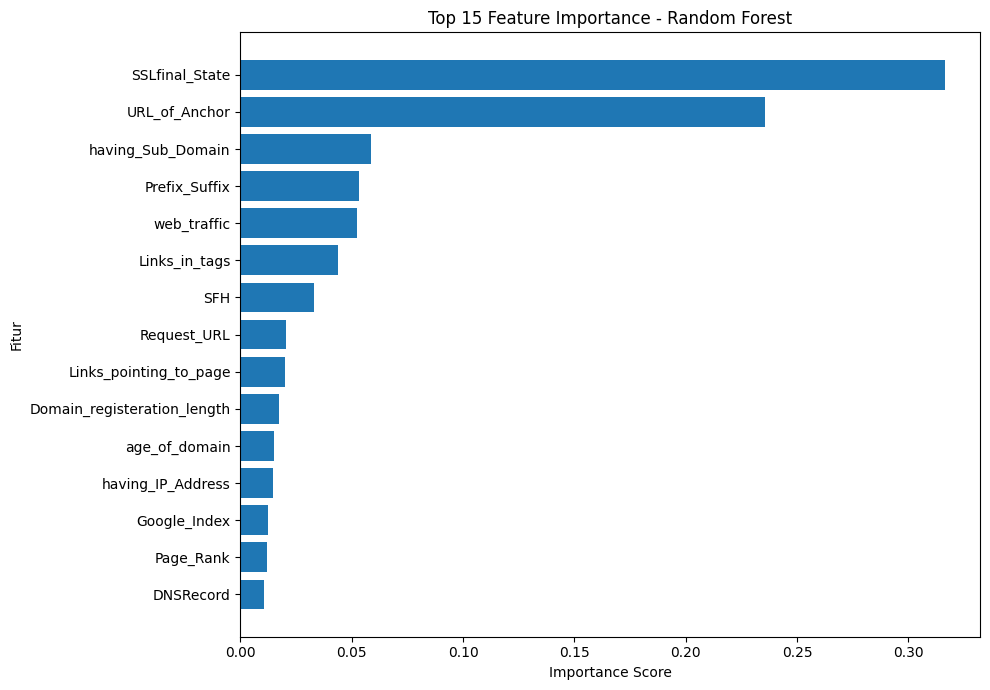

In [20]:

# Analisis Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Mengambil nilai kepentingan setiap fitur
feature_importance = pd.DataFrame({
    "Fitur": X_train.columns,
    "Importance": model_rf_final.feature_importances_
})

# Mengurutkan fitur dari yang paling berpengaruh
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Menampilkan 15 fitur teratas
print("===== TOP 15 FEATURE IMPORTANCE =====")
display(feature_importance.head(15).round(4))

# Membuat visualisasi
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance.head(15)["Fitur"][::-1],
    feature_importance.head(15)["Importance"][::-1]
)

plt.xlabel("Importance Score")
plt.ylabel("Fitur")
plt.title("Top 15 Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

  Legitimate       0.93      0.96      0.94       566
    Phishing       0.96      0.93      0.94       604

    accuracy                           0.94      1170
   macro avg       0.94      0.94      0.94      1170
weighted avg       0.94      0.94      0.94      1170



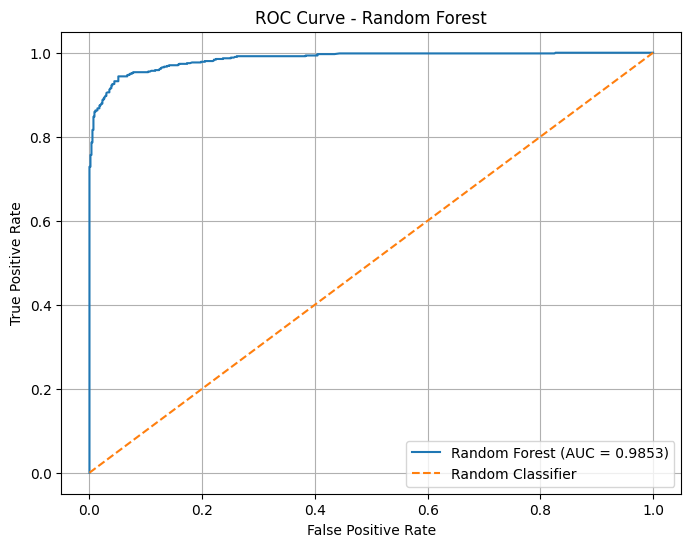

In [21]:

# Evaluasi Akhir Random Forest

from sklearn.metrics import classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Classification Report
print("===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test.values.ravel(),
    y_pred_final,
    target_names=["Legitimate", "Phishing"]
))

# Menghitung probabilitas prediksi
y_pred_proba = model_rf_final.predict_proba(X_test)[:, 1]

# Menghitung ROC Curve dan AUC
fpr, tpr, thresholds = roc_curve(
    y_test.values.ravel(),
    y_pred_proba
)

auc_score = roc_auc_score(
    y_test.values.ravel(),
    y_pred_proba
)

# Visualisasi ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid()
plt.show()

In [22]:

# Menyimpan Model Random Forest

import joblib
import os

# Membuat folder models jika belum tersedia
os.makedirs("models", exist_ok=True)

# Menyimpan model final
joblib.dump(
    model_rf_final,
    "models/random_forest_model.pkl"
)

print("===== PENYIMPANAN MODEL =====")
print("Model berhasil disimpan!")
print("Lokasi: models/random_forest_model.pkl")

===== PENYIMPANAN MODEL =====
Model berhasil disimpan!
Lokasi: models/random_forest_model.pkl


In [23]:

# Memuat kembali model yang sudah disimpan

model_rf_loaded = joblib.load(
    "models/random_forest_model.pkl"
)

# Melakukan prediksi menggunakan model yang dimuat
y_pred_loaded = model_rf_loaded.predict(X_test)

# Memeriksa apakah hasil prediksi sama
hasil_sama = (y_pred_loaded == y_pred_final).all()

print("===== PENGUJIAN MODEL TERSIMPAN =====")
print("Model berhasil dimuat!")
print("Prediksi konsisten:", hasil_sama)

===== PENGUJIAN MODEL TERSIMPAN =====
Model berhasil dimuat!
Prediksi konsisten: True



## Kesimpulan Random Forest

Berdasarkan hasil eksperimen, algoritma Random Forest berhasil digunakan untuk mengklasifikasikan website ke dalam kategori Legitimate dan Phishing.

Pengujian dilakukan dengan membandingkan jumlah pohon sebanyak 50, 100, 200, dan 300. Berdasarkan hasil evaluasi, konfigurasi 300 pohon memberikan hasil terbaik berdasarkan nilai Recall, F1-Score, dan ROC-AUC.

Model final kemudian dilatih menggunakan konfigurasi terbaik dan dievaluasi menggunakan Confusion Matrix, Classification Report, serta ROC Curve.

Selain itu, analisis Feature Importance dilakukan untuk mengetahui fitur-fitur yang paling berpengaruh dalam proses klasifikasi.

Model final berhasil disimpan dalam format .pkl sehingga dapat digunakan kembali tanpa perlu melakukan training ulang.
